# Matrix factorization with parallel seeds

Compare gradient descent, LeAP-SSN, GLAd-SSN and cubic Newton across random
seeds. Each worker runs all methods for one seed, using the same data and
starting factors. The default is six seeds. This is the parallel version of
`experiment_matrix_factorization_multiple_cubic_new.ipynb`.

Run from the repository root or `MF` directory. In a kernel with NumPy, SciPy
and Matplotlib, install the extra dependencies if needed:

```python
%pip install "joblib>=1.3,<2" threadpoolctl galahad-optrove==5.5.3
```

1. Choose the settings below. Use the small example for a quick check.
2. Run the notebook from top to bottom.
3. Check the solver status table, then compare the plots.

We fit `U @ V` to a fixed observed matrix `M_obs`, minimizing

$$F(U,V)=\frac12\|UV-M_{\mathrm{obs}}\|_F^2
  +\frac{\alpha}{2}(\|U\|_F^2+\|V\|_F^2)
  +\frac{\beta}{2}(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$

`U` has shape `(m, r)` and `V` has shape `(r, n)`.
Here $(-U)_+=\max(-U,0)$: negative entries are penalized, not forbidden.
The synthetic data are `M_obs = U_true @ V_true + Gaussian noise`;
true factor entries are uniform on `[0, 1)`. Only the fitted factors change
during optimization.

The reference is [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1),
Section 5.2 / Appendix E.2. GLAd corresponds to Algorithm 1 and subproblem (2).
The public objective is equation (28); the repository uses the weights above.
Cubic Newton is an extra comparison. Current settings differ from the paper,
so this notebook is not a full reproduction.

| Paper figure | Input from `all_seeds_histories`, then `averaged_history` |
| --- | --- |
| Figure 3: nonnegativity violation | `penalty` |
| Figure 4: gradient norm | `grad_norm` |
| Figure 6: objective residual | `func` minus the plotting reference |

The final combined comparison reads the individual histories directly.


In [219]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton_nonconvex_new
from oracles_mat_fac import PositiveMatrixFactorization
from utils_new import plot_figures

from joblib import cpu_count
from joblib.externals.loky import ProcessPoolExecutor
from concurrent.futures import wait, FIRST_COMPLETED
from IPython.display import HTML, display
from time import perf_counter
import heapq
import html
import importlib.metadata
import platform

%matplotlib inline

## Settings

| Setting | Meaning |
| --- | --- |
| `seeds_to_try` | Seeds for data and initialization; shared by all methods within each seed. |
| `m`, `n`, `r` | Matrix rows, columns and factorization rank. |
| `noise` | Standard deviation of the added Gaussian noise. Zero gives noiseless data. |
| `alpha`, `beta` | Ridge and nonnegativity weights in the objective above. |
| `initial_factor_std` | Standard deviation of the zero-mean Gaussian starting factors. |
| `gradient_iterations`, `number_of_iterations` | Maximum updates for gradient descent and each Newton method. |
| `grad_tol` | Stop when the full Euclidean gradient norm is at most this value. Default `1e-10`; `None` disables this tolerance. |
| `initial_lambda` | Initial shift in `Hessian + lambda * I` for LeAP and GLAd. GLAd later scales its shift with the gradient norm raised to `p`. |
| `lss_method`, `lss_tol`, `lss_maxiters` | Linear solver, requested relative tolerance and iteration cap. Default: MINRES. |
| `cubic_initial_H` | Initial cubic parameter; the model term is `H / 6 * ||step||**3`. |
| `cubic_subproblem_tol` | GLRT model-gradient residual tolerance relative to the outer gradient norm, with a roundoff allowance. |
| `cubic_glrt_max_iter` | GLRT iteration cap per trial. Reconstruction and checks require extra Hessian-vector products. |
| `cubic_max_backtracks` | Maximum rejected trials per outer update, after one initial trial. |
| `gn_exponents` | GLAd exponents included in the exact/Gauss-Newton comparison. LeAP is always included. |
| `plot_threshold` | Trims the six mean plots; does not stop a solver. |
| `SAVE_FIGURES` | Save the six mean plots as PDFs. Histories stay in memory. |

### Methods and stopping

The notebook runs 11 methods: gradient descent, LeAP, five GLAd exponents
(`0.2, 0.4, 0.5, 0.6, 0.8`), cubic Newton, and three Gauss-Newton variants.
LeAP and GLAd use fresh exact generalized Hessians and inexact MINRES solves.
The Gauss-Newton variants keep the same data, start and solver settings;
their curvature approximation includes ridge and penalty terms.

Every method checks `grad_tol` at the initial point and after each accepted
update, before doing more work. The stopping point stays in the history.
`success` means the gradient target was reached; it does not certify a local
minimum. `iterations_exceeded` means the budget ran out. Failures above the
target keep their failure status. No objective stopping tolerance is used.

The shared `grad_tol` is a local experiment setting, not a paper revision.
It shortens runs after the first threshold crossing without changing earlier
updates. Hessian reuse, regularization, acceptance tests, initialization,
seeds and inner-solve tolerances are unchanged. Rerun the experiment after
changing this setting.

### Cubic Newton

The cubic baseline uses [GALAHAD GLRT](CUBIC_SUBPROBLEM.md) with Hessian-vector
products. It approximately minimizes the model with cubic term
`H_k / 6 * ||step||**3`, then accepts when `f(x + step) <= f(x) + model_change`.
Rejected trials double `H_k`; accepted trials halve it, with floor `1e-5`.
Each new iterate gets a fresh generalized Hessian; rejected trials reuse it.
GLRT failure returns the last accepted iterate. Check exit statuses and the
recorded gradient norm before interpreting convergence. Runtime includes
rejected trials; the inexact subproblem solve does not certify a global minimum.

### Parallel run and quick check

`N_JOBS=6` requests six workers, capped by CPU availability, thread budget
and seed count. `THREADS_PER_WORKER=1` limits BLAS/OpenMP threads;
`PROGRESS_INTERVAL=2.0` refreshes progress about every two seconds.
Use `N_JOBS=1` for a sequential run. Threading can affect numerical reductions
and timing, so keep the same thread limit when comparing runs.

For a quick check, use `m, n, r = 6, 4, 2`, seeds `[549, 498]`,
`gradient_iterations=20` and `number_of_iterations=5`.


In [ ]:
# Original recorded seeds (uncomment for the 20-seed experiment):
#seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
#seeds_to_try = [344]
seeds_to_try = [549, 498, 483, 33, 528, 989]


# Data and objective
m, n, r = 200, 100, 12

m, n, r = 50, 25, 4

noise = 0.2
alpha, beta = 0.01, 500.0
initial_factor_std = 0.05

# Iteration budgets and regularization
gradient_iterations = 8000       # Original long run: 3_000_000
number_of_iterations = 2000       # Original long run: 12_000
grad_tol = 1e-8  # Absolute outer gradient norm; None disables this tolerance.
initial_lambda = 10.0
lss_method = "minres"  # SciPy MINRES; GLRT keeps its compiled GALAHAD backend.
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 6000  # Per-trial cap; unchanged from the source notebook.
cubic_max_backtracks = 120

# Plotting and optional export
plot_threshold = 1e-8
SAVE_FIGURES = False

if not seeds_to_try or len(seeds_to_try) != len(set(seeds_to_try)):
    raise ValueError("Provide a nonempty list of distinct seeds.")
print("Trying seeds:", seeds_to_try)

# Parallel execution: choose multiple seeds above to use multiple workers.
N_JOBS = 6 # determine the number of parallel workers; set to 1 for sequential execution
THREADS_PER_WORKER = 1 #determine the number of threads per worker; set to 1 for sequential execution
PROGRESS_INTERVAL = 2.0 


Trying seeds: [549, 498, 483, 33, 528, 989]


## Run one seed

Each worker creates its own NumPy random state and runs the methods in order.
Histories, cubic work counts and exit statuses are returned to the notebook.
Solver failures keep the last accepted history; Python exceptions stop the
batch and identify the seed and method. No checkpoints are written.


In [221]:
def run_one_seed(seed, settings, mf_directory, threads=1):
    """Run one independent seed with the original data draws and method order.

    m, n, r specify M:(m,n), U:(m,r), V:(r,n); packed iterates have (m+n)*r
    entries. Return plotting histories, cubic work statistics, exit statuses,
    method wall times, and the actual worker thread-pool configuration.
    """
    # Import inside the worker; only the seed/configuration cross processes.
    import contextlib
    import io
    import os
    import sys
    from time import perf_counter
    sys.dont_write_bytecode = True
    if mf_directory not in sys.path:
        sys.path.insert(0, mf_directory)
    import numpy as np
    from threadpoolctl import threadpool_limits, threadpool_info
    from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton_nonconvex_new
    from oracles_mat_fac import PositiveMatrixFactorization
    from galahad import glrt  # Load native libraries before limiting threads.

    seed_started = perf_counter()
    with threadpool_limits(limits=threads):
        m = settings['m']
        n = settings['n']
        r = settings['r']
        noise = settings['noise']
        alpha = settings['alpha']
        beta = settings['beta']
        initial_factor_std = settings['initial_factor_std']
        gradient_iterations = settings['gradient_iterations']
        number_of_iterations = settings['number_of_iterations']
        grad_tol = settings['grad_tol']
        initial_lambda = settings['initial_lambda']
        lss_method = settings['lss_method']
        lss_tol = settings['lss_tol']
        lss_maxiters = settings['lss_maxiters']
        gn_exponents = settings['gn_exponents']
        cubic_initial_H = settings['cubic_initial_H']
        cubic_subproblem_tol = settings['cubic_subproblem_tol']
        cubic_glrt_max_iter = settings['cubic_glrt_max_iter']
        cubic_max_backtracks = settings['cubic_max_backtracks']

        rng = np.random.RandomState(seed)  # Same MT19937 sequence as np.random.seed(seed).

        # Ground truth
        U_true = rng.rand(m, r)
        V_true = rng.rand(n, r).T  # (r, n); preserve the previous random draw
        M_clean = U_true @ V_true

        # Noisy observed matrix
        M_obs = M_clean + noise * rng.randn(m, n)

        # Gaussian starting factors, shared by every method for this seed.
        # Keep the original draw order while storing V with shape (r, n).
        initial_values = initial_factor_std * rng.randn(m * r + n * r)
        U_0 = initial_values[:m*r].reshape(m, r)
        V_0 = initial_values[m*r:].reshape(n, r).T

        oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
        x_0 = oracle.pack(U_0, V_0)

        methods_to_run = {
            'Gradient Method': (
                gradient_method, (oracle, x_0),
                dict(
                    max_iter=gradient_iterations,
                    grad_tol=grad_tol,
                    warnings=False,
                ),
            ),
            'LeAP-SSN': (
                mf_leapssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
            'GLAd-SSN, p=0.2': (
                mf_gladssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    p=0.2,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
            'GLAd-SSN, p=0.4': (
                mf_gladssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    p=0.4,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
            'GLAd-SSN, p=0.5': (
                mf_gladssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    p=0.5,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
            'GLAd-SSN, p=0.6': (
                mf_gladssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    p=0.6,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
            'GLAd-SSN, p=0.8': (
                mf_gladssn, (oracle, x_0),
                dict(
                    n_iters=number_of_iterations,
                    grad_tol=grad_tol,
                    H_0=initial_lambda,
                    warnings=False,
                    p=0.8,
                    lss_tol=lss_tol,
                    lss_maxiters=lss_maxiters,
                    lss_method=lss_method,
                    use_gauss_newton=False,
                ),
            ),
        }

        methods_to_run["Cubic Newton (GLRT)"] = (
            cubic_newton_nonconvex_new, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                grad_tol=grad_tol,
                H_0=cubic_initial_H,
                subproblem_tol=cubic_subproblem_tol,
                glrt_max_iter=cubic_glrt_max_iter,
                max_backtracks=cubic_max_backtracks,
                warnings=False,
            ),
        )

        # Add Gauss-Newton copies of the same LeAP/GLAd methods as the source notebook.
        original_method_names = list(methods_to_run)
        gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]
        for method_name in gn_base_names:
            solver, args, options = methods_to_run[method_name]
            methods_to_run[f"{method_name} (GN)"] = (
                solver, args, dict(options, use_gauss_newton=True)
            )


        plot_keys = ("func", "time", "grad_norm", "penalty")
        seed_histories, statuses, method_seconds = {}, {}, {}
        cubic_diagnostics = {}
        for name, (solver, args, options) in methods_to_run.items():
            method_started = perf_counter()
            try:
                with contextlib.redirect_stdout(io.StringIO()):
                    _, status, history = solver(*args, **options)
            except Exception as error:
                raise RuntimeError(f"Seed {seed}, method {name!r} failed") from error
            method_seconds[name] = perf_counter() - method_started
            statuses[name] = status
            seed_histories[name] = {
                key: np.asarray(history[key]) for key in plot_keys
            }
            if name == "Cubic Newton (GLRT)":
                cubic_diagnostics = {
                    key: np.asarray(history[key])
                    for key in ("hess_vec_calls", "glrt_iterations", "glrt_status",
                                "subproblem_relative_residual", "subproblem_calls", "H_k")
                    if key in history
                }
            del history
        thread_pools = threadpool_info()
        return dict(
            seed=int(seed), histories=seed_histories, cubic=cubic_diagnostics,
            statuses=statuses, method_seconds=method_seconds,
            seed_seconds=perf_counter() - seed_started,
            original_method_names=original_method_names, thread_pools=thread_pools,
            pid=os.getpid(),
        )


## Run the batch

The live display shows completed, running and queued seeds, elapsed time and
an estimated time remaining. Estimates start after the first completed seed and can be optimistic.

Batch time includes worker startup and shutdown. Plotted times are per-method
elapsed times while workers share the CPU, not isolated timing benchmarks.
The status table reports each method's exit, final gradient norm and wall time.
Review failures before interpreting the plots. Interrupting the cell stops
unfinished workers and retains completed results in memory.


In [222]:
def format_duration(seconds):
    seconds = max(0, int(round(seconds)))
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:d}h {minutes:02d}m {seconds:02d}s"


def estimate_remaining(completed_seconds, active_ages, queued, workers):
    """Estimate remaining wall seconds by scheduling onto predicted free slots.

    Completed durations and active ages are measured from submission to receipt,
    in seconds. None means insufficient observations or an overdue active seed.
    """
    if not active_ages and queued == 0:
        return 0.0, "complete"
    if not completed_seconds:
        return None, "waiting for the first completed seed"
    mean_seconds = float(np.mean(completed_seconds))
    if any(age >= mean_seconds for age in active_ages):
        return None, "uncertain: an active seed exceeds the observed mean"
    loads = [mean_seconds - age for age in active_ages]
    loads.extend([0.0] * (workers - len(loads)))
    heapq.heapify(loads)
    for _ in range(queued):
        available = heapq.heappop(loads)
        heapq.heappush(loads, available + mean_seconds)
    return max(loads), f"rough estimate from {len(completed_seconds)} completed seed(s)"


def render_progress(completed, active, queued, total, elapsed, eta, note, state="running"):
    running = ", ".join(str(seed) for seed in active) or "none"
    remaining = format_duration(eta) if eta is not None else "estimating"
    return HTML(
        f"<progress value='{completed}' max='{total}' style='width:100%'></progress>"
        f"<p><b>{completed}/{total} seeds complete</b> | {html.escape(state)}"
        f"<br>Elapsed: <b>{format_duration(elapsed)}</b>"
        f" | Remaining: <b>{remaining}</b>"
        f"<br>{html.escape(note)}"
        f"<br>Running: {html.escape(running)} | Queued: {queued}</p>"
    )


In [223]:
batch_complete = False  # Invalidate any previous completed batch before validation.
# Validate before launching workers.
if grad_tol is not None and (
    isinstance(grad_tol, (bool, np.bool_))
    or not isinstance(grad_tol, (int, float, np.integer, np.floating))
    or not np.isfinite(grad_tol) or grad_tol < 0
):
    raise ValueError("grad_tol must be a finite nonnegative real scalar, or None.")
for label, value in (("N_JOBS", N_JOBS), ("THREADS_PER_WORKER", THREADS_PER_WORKER)):
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{label} must be a positive integer.")
if not np.isfinite(PROGRESS_INTERVAL) or PROGRESS_INTERVAL <= 0:
    raise ValueError("PROGRESS_INTERVAL must be finite and positive.")
if not seeds_to_try or len(set(seeds_to_try)) != len(seeds_to_try):
    raise ValueError("Provide a nonempty list of distinct seeds.")
if any(isinstance(seed, bool) or not isinstance(seed, (int, np.integer))
       or not 0 <= seed < 2**32 for seed in seeds_to_try):
    raise ValueError("Seeds must be integers in [0, 2**32).")
if THREADS_PER_WORKER > cpu_count():
    raise ValueError("THREADS_PER_WORKER exceeds the available CPU count.")

experiment_config = {
    'm': m,
    'n': n,
    'r': r,
    'noise': noise,
    'alpha': alpha,
    'beta': beta,
    'initial_factor_std': initial_factor_std,
    'gradient_iterations': gradient_iterations,
    'number_of_iterations': number_of_iterations,
    'grad_tol': grad_tol,
    'initial_lambda': initial_lambda,
    'lss_method': lss_method,
    'lss_tol': lss_tol,
    'lss_maxiters': lss_maxiters,
    'gn_exponents': gn_exponents,
    'cubic_initial_H': cubic_initial_H,
    'cubic_subproblem_tol': cubic_subproblem_tol,
    'cubic_glrt_max_iter': cubic_glrt_max_iter,
    'cubic_max_backtracks': cubic_max_backtracks,
}
experiment_config["gn_exponents"] = list(gn_exponents)
gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in experiment_config["gn_exponents"]]

effective_workers = min(int(N_JOBS), len(seeds_to_try),
                        max(1, cpu_count() // int(THREADS_PER_WORKER)))
print(f"Using {effective_workers} process(es), {THREADS_PER_WORKER} numerical-library "
      f"thread(s) each; {cpu_count()} logical CPUs available.")
if len(seeds_to_try) == 1:
    print("Only one seed is selected. Enable the multi-seed list above for parallel work.")

plot_keys = ("func", "time", "grad_norm", "penalty")
all_seeds_histories = {}
all_seeds_cubic_diagnostics = {}
all_seeds_statuses = {}
all_seeds_timing = {}
original_method_names = None
run_metadata = {
    "started_at": datetime.now().astimezone().isoformat(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "packages": {name: importlib.metadata.version(name)
                 for name in ("numpy", "scipy", "joblib", "threadpoolctl", "galahad-optrove")},
    "precision": "float64",
    "seeds": [int(seed) for seed in seeds_to_try],
    "configuration": dict(experiment_config),
    "requested_workers": int(N_JOBS),
    "effective_workers": effective_workers,
    "threads_per_worker": int(THREADS_PER_WORKER),
    "state": "running",
}
# These are applied before workers import NumPy/SciPy/GALAHAD. The worker also
# uses threadpoolctl, so supported native libraries are capped during solves.
worker_environment = {
    name: str(THREADS_PER_WORKER)
    for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "BLIS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS")
}
worker_environment["PYTHONDONTWRITEBYTECODE"] = "1"

batch_started = perf_counter()
completed_turnarounds = []
pending = {}
next_seed_index = 0
progress = display(render_progress(0, [], len(seeds_to_try), len(seeds_to_try),
                                  0, None, "starting workers"), display_id=True)
executor = None
try:
    executor = ProcessPoolExecutor(max_workers=effective_workers, env=worker_environment)
    while next_seed_index < len(seeds_to_try) or pending:
        # Bound submissions so active ages include startup, but no long queue wait.
        while next_seed_index < len(seeds_to_try) and len(pending) < effective_workers:
            seed = int(seeds_to_try[next_seed_index])
            submitted_at = perf_counter()
            future = executor.submit(run_one_seed, seed, experiment_config,
                                     str(MF_DIR.resolve()), int(THREADS_PER_WORKER))
            pending[future] = (seed, submitted_at)
            next_seed_index += 1

        finished, _ = wait(pending, timeout=PROGRESS_INTERVAL, return_when=FIRST_COMPLETED)
        errors = []
        for future in finished:
            seed, submitted_at = pending.pop(future)
            received_at = perf_counter()
            try:
                result = future.result()
            except Exception as error:
                errors.append((seed, error))
                continue
            turnaround = received_at - submitted_at
            completed_turnarounds.append(turnaround)
            all_seeds_histories[seed] = result["histories"]
            all_seeds_cubic_diagnostics[seed] = result["cubic"]
            all_seeds_statuses[seed] = result["statuses"]
            all_seeds_timing[seed] = {
                "turnaround_seconds": turnaround,
                "seed_seconds": result["seed_seconds"],
                "method_seconds": result["method_seconds"],
                "thread_pools": result["thread_pools"],
                "pid": result["pid"],
            }
            if original_method_names is None:
                original_method_names = result["original_method_names"]
            elif original_method_names != result["original_method_names"]:
                raise RuntimeError("Method order differs across seeds.")

        if errors:
            seed, error = errors[0]
            raise RuntimeError(
                f"Seed {seed} raised an exception. Completed results remain in "
                "all_seeds_histories; the batch will not be plotted as complete."
            ) from error

        now = perf_counter()
        queued = len(seeds_to_try) - next_seed_index
        ages = [now - submitted for _, submitted in pending.values()]
        eta, note = estimate_remaining(completed_turnarounds, ages, queued, effective_workers)
        progress.update(render_progress(
            len(all_seeds_histories), [seed for seed, _ in pending.values()],
            queued, len(seeds_to_try), now - batch_started, eta, note))

    batch_complete = True
    run_metadata["state"] = "complete"
except KeyboardInterrupt:
    run_metadata["state"] = "interrupted"
    raise
except BaseException:
    run_metadata["state"] = "failed"
    raise
finally:
    if executor is not None:
        # A stopped/failed cell terminates its processes instead of leaving
        # expensive seeds running in the background.
        executor.shutdown(wait=True, kill_workers=not batch_complete)
    batch_elapsed_seconds = perf_counter() - batch_started
    run_metadata["batch_elapsed_seconds"] = batch_elapsed_seconds
    run_metadata["completed_seeds"] = list(all_seeds_histories)
    progress.update(render_progress(
        len(all_seeds_histories), [], len(seeds_to_try) - len(all_seeds_histories),
        len(seeds_to_try), batch_elapsed_seconds, 0 if batch_complete else None,
        "all seed calculations returned" if batch_complete else
        "unfinished workers stopped; completed results remain in memory",
        run_metadata["state"]))

# Restore requested seed order so completion order cannot affect averaging/plots.
all_seeds_histories = {seed: all_seeds_histories[seed] for seed in seeds_to_try}
all_seeds_cubic_diagnostics = {seed: all_seeds_cubic_diagnostics[seed] for seed in seeds_to_try}
all_seeds_statuses = {seed: all_seeds_statuses[seed] for seed in seeds_to_try}
all_seeds_timing = {seed: all_seeds_timing[seed] for seed in seeds_to_try}
print("Batch wall time (startup through shutdown):", format_duration(batch_elapsed_seconds))
print("Outer gradient tolerance:", grad_tol)
print("iterations_exceeded means the iteration budget was reached, not verified convergence.")
status_rows = "".join(
    "<tr><td>" + str(seed) + "</td><td>" + html.escape(method) + "</td><td>"
    + html.escape(status) + "</td><td>"
    + f"{all_seeds_histories[seed][method]['grad_norm'][-1]:.3e}" + "</td><td>"
    + format_duration(all_seeds_timing[seed]["method_seconds"][method]) + "</td></tr>"
    for seed in seeds_to_try for method, status in all_seeds_statuses[seed].items()
)
display(HTML("<details><summary>Solver exit statuses and measured method times</summary>"
             "<table><tr><th>Seed</th><th>Method</th><th>Status</th><th>Final gradient norm</th><th>Wall time</th></tr>"
             + status_rows + "</table></details>"))
unusual_exits = [(seed, method, status) for seed, statuses in all_seeds_statuses.items()
                 for method, status in statuses.items()
                 if status != "iterations_exceeded"
                 and status != "success" and not status.startswith("success, ")]
if unusual_exits:
    print("Review these solver exits before interpreting the plots:")
    for seed, method, status in unusual_exits:
        print(f"  seed {seed}: {method}: {status}")


Using 6 process(es), 1 numerical-library thread(s) each; 16 logical CPUs available.


Batch wall time (startup through shutdown): 0h 00m 54s
Outer gradient tolerance: 1e-08
iterations_exceeded means the iteration budget was reached, not verified convergence.


Seed,Method,Status,Final gradient norm,Wall time
549,Gradient Method,iterations_exceeded,8.278e-02,0h 00m 01s
549,LeAP-SSN,"success, 129 iters",1.006e-09,0h 00m 01s
549,"GLAd-SSN, p=0.2","success, 261 iters",2.175e-09,0h 00m 02s
549,"GLAd-SSN, p=0.4","success, 218 iters",2.215e-09,0h 00m 02s
549,"GLAd-SSN, p=0.5","success, 208 iters",2.088e-09,0h 00m 01s
549,"GLAd-SSN, p=0.6","success, 148 iters",4.631e-10,0h 00m 01s
549,"GLAd-SSN, p=0.8","success, 231 iters",9.478e-10,0h 00m 02s
549,Cubic Newton (GLRT),"success, 68 iters",1.834e-09,0h 00m 01s
549,LeAP-SSN (GN),"numerical_stagnation, 831 iters",7.467e-08,0h 00m 11s
549,"GLAd-SSN, p=0.2 (GN)","numerical_stagnation, 856 iters",6.413e-08,0h 00m 13s


Review these solver exits before interpreting the plots:
  seed 549: LeAP-SSN (GN): numerical_stagnation, 831 iters
  seed 549: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 856 iters
  seed 549: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 895 iters
  seed 498: LeAP-SSN (GN): numerical_stagnation, 454 iters
  seed 498: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 617 iters
  seed 498: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 594 iters
  seed 483: LeAP-SSN (GN): numerical_stagnation, 424 iters
  seed 483: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 765 iters
  seed 483: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 789 iters
  seed 33: LeAP-SSN (GN): numerical_stagnation, 408 iters
  seed 33: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 436 iters
  seed 33: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 466 iters
  seed 528: LeAP-SSN (GN): numerical_stagnation, 332 iters
  seed 528: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 427 iters
  seed 528: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 4

## Average the seeds

Average matching iterations across all seeds. Each method's mean curve ends
at its shortest run, so no stopped seed is silently dropped. Runtime plots
pair the mean metric with the mean time at that iteration.


In [224]:
if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete every requested seed before averaging.")
template_seed = seeds_to_try[0]
averaged_history = {
    method_name: {
        measure: np.zeros_like(history[measure], dtype=float)
        for measure in plot_keys
    }
    for method_name, history in all_seeds_histories[template_seed].items()
}

def add_common(a, b):
    """Add arrays only through the shorter run's last recorded iteration."""
    n = min(len(a), len(b))
    return a[:n] + b[:n]

for seed in seeds_to_try:
    for method_name, history in all_seeds_histories[seed].items():
        for measure in plot_keys:
            averaged_history[method_name][measure] = add_common(
                averaged_history[method_name][measure], history[measure]
            )

for method_name in averaged_history:
    for measure in plot_keys:
        averaged_history[method_name][measure] /= len(seeds_to_try)
    print(method_name, ": averaging all seeds through iteration",
          len(averaged_history[method_name]["func"]) - 1)

Gradient Method : averaging all seeds through iteration 3000
LeAP-SSN : averaging all seeds through iteration 129
GLAd-SSN, p=0.2 : averaging all seeds through iteration 171
GLAd-SSN, p=0.4 : averaging all seeds through iteration 196
GLAd-SSN, p=0.5 : averaging all seeds through iteration 166
GLAd-SSN, p=0.6 : averaging all seeds through iteration 148
GLAd-SSN, p=0.8 : averaging all seeds through iteration 167
Cubic Newton (GLRT) : averaging all seeds through iteration 52
LeAP-SSN (GN) : averaging all seeds through iteration 332
GLAd-SSN, p=0.2 (GN) : averaging all seeds through iteration 427
GLAd-SSN, p=0.5 (GN) : averaging all seeds through iteration 421


## Mean results

These three figures compare the original seven methods and cubic Newton:
objective residual, gradient norm and weighted penalty, against iteration and
mean runtime. The objective reference is the best observed mean among these
eight methods, not a known global optimum. `plot_threshold` trims objective
and gradient curves only. Penalty curves keep every recorded point, including
zeros; their scale is linear below `plot_threshold` and logarithmic above it.


In [225]:
histories = {name: averaged_history[name] for name in original_method_names}
#line_widths = [2.5] * len(histories)
line_widths = [2.0] * len(histories)
line_styles = ["-"] * len(histories)
colors = ["#E8601C", "black", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF", "#A97900"]
mn_func = min(np.min(history["func"]) for history in histories.values())
figures = {}

Last Mean objective - best observed mean of Gradient Method: 0.04303201136002954
Last Mean objective - best observed mean of LeAP-SSN: 0.020258846785193185
Last Mean objective - best observed mean of GLAd-SSN, p=0.2: 0.012855605943737913
Last Mean objective - best observed mean of GLAd-SSN, p=0.4: 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.5: 0.007157730543834617
Last Mean objective - best observed mean of GLAd-SSN, p=0.6: 0.025298710889526177
Last Mean objective - best observed mean of GLAd-SSN, p=0.8: 0.012201422898499459
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.016779063533153504


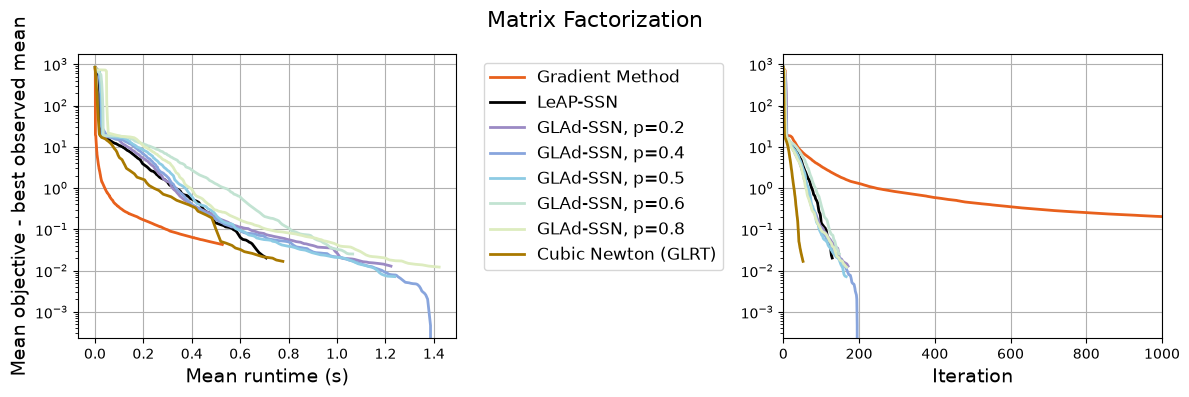

Last Mean gradient norm of Gradient Method: 0.06608807299836876
Last Mean gradient norm of LeAP-SSN: 0.03938894054973558
Last Mean gradient norm of GLAd-SSN, p=0.2: 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.4: 0.013271200536756978
Last Mean gradient norm of GLAd-SSN, p=0.5: 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.6: 0.043329752313103716
Last Mean gradient norm of GLAd-SSN, p=0.8: 0.007740908033196644
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358


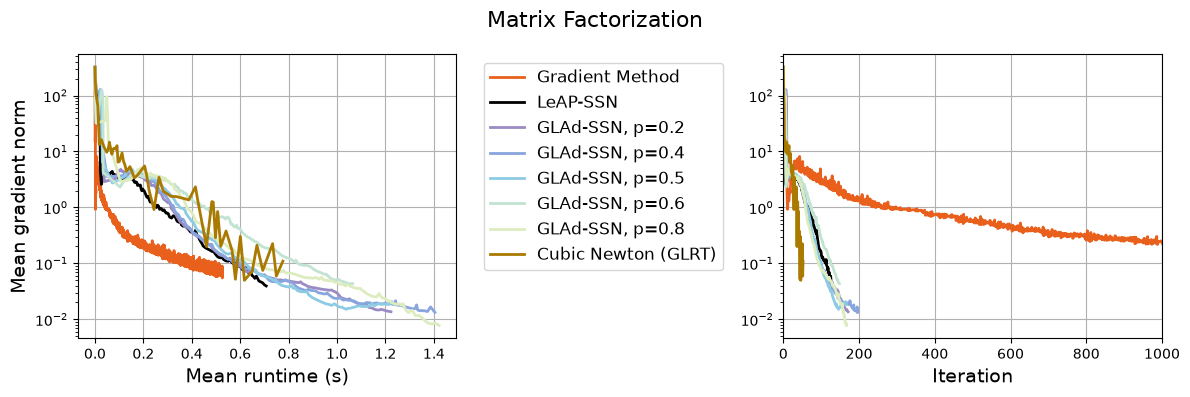

Last Mean penalty of Gradient Method: 0.0012443625899930756
Last Mean penalty of LeAP-SSN: 0.0009347193913061578
Last Mean penalty of GLAd-SSN, p=0.2: 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.4: 0.0009002549247987057
Last Mean penalty of GLAd-SSN, p=0.5: 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.6: 0.0009804634788328878
Last Mean penalty of GLAd-SSN, p=0.8: 0.0010326062662225522
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809


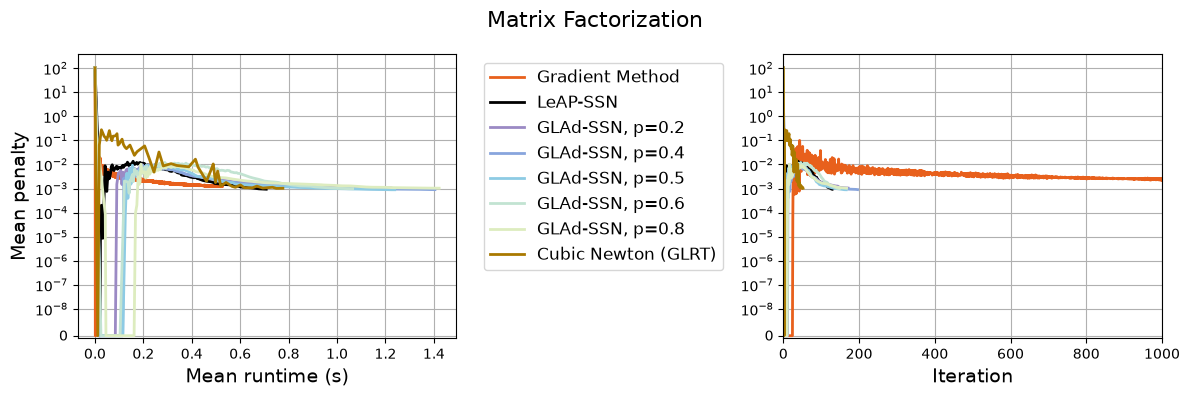

In [226]:
figures["func"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=mn_func, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="func", which_measure_2="func",
    ylabel="Mean objective - best observed mean",
)
plt.show()
plt.close(figures["func"])


figures["grad_norm"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="grad_norm", which_measure_2="grad_norm",
    ylabel="Mean gradient norm",
)
plt.show()
plt.close(figures["grad_norm"])


figures["penalty"] = plot_figures(
    list(histories.values()), list(histories.keys()),
    colors=colors, linewidths=line_widths, linestyles=line_styles,
    n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
    f_star=0, threshold=plot_threshold,
    suptitle="Matrix Factorization", max_iter=number_of_iterations,
    which_measure_1="penalty", which_measure_2="penalty",
    ylabel="Mean penalty",
)
plt.show()
plt.close(figures["penalty"])

## Exact Hessian and Gauss-Newton

Compare LeAP and the selected GLAd exponents, keeping gradient descent and
cubic Newton as baselines. Solid lines use exact generalized Hessians;
dashed lines use Gauss-Newton. Matching methods share colors, data and starts.
These three figures use their own best observed mean objective as the
reference; the previous figures keep theirs.


Last Mean objective - best observed mean of Gradient Method: 0.05211496577859975
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.025862017951723715
Last Mean objective - best observed mean of LeAP-SSN (exact): 0.029341801203763396
Last Mean objective - best observed mean of LeAP-SSN (GN): 0.0039640529349398435
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (exact): 0.021938560362308124
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (GN): 0.0021107629392673743
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (exact): 0.016240684962404828
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (GN): 0.0


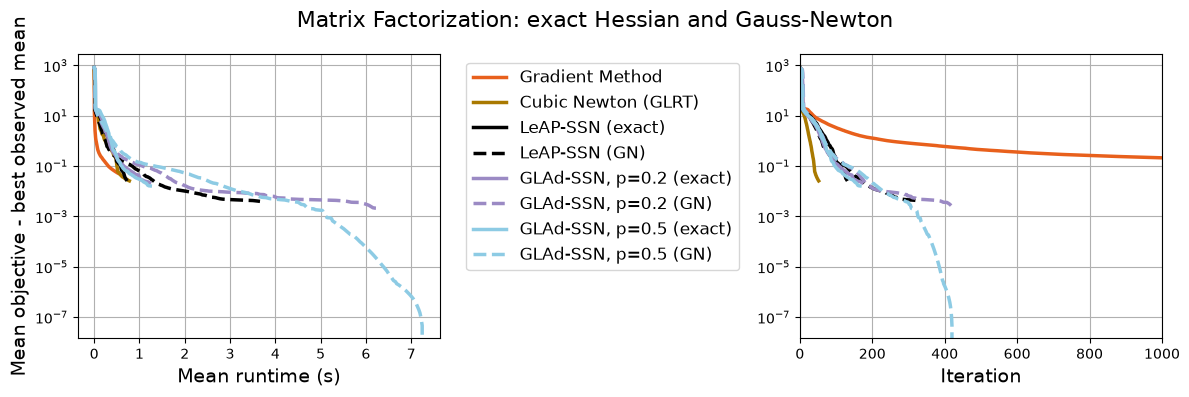

Last Mean gradient norm of Gradient Method: 0.06608807299836876
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358
Last Mean gradient norm of LeAP-SSN (exact): 0.03938894054973558
Last Mean gradient norm of LeAP-SSN (GN): 0.002251705932689568
Last Mean gradient norm of GLAd-SSN, p=0.2 (exact): 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.2 (GN): 0.0030181054850820076
Last Mean gradient norm of GLAd-SSN, p=0.5 (exact): 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.5 (GN): 0.00013361577150834865


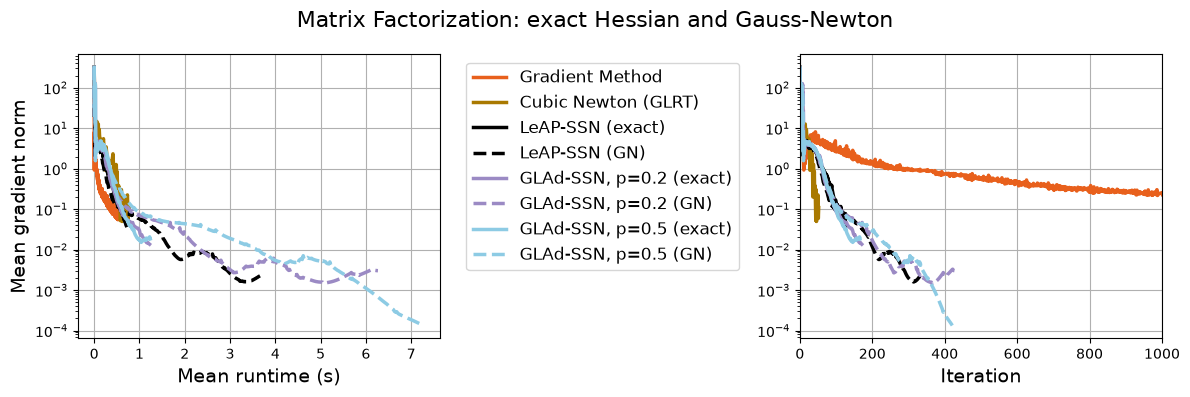

Last Mean penalty of Gradient Method: 0.0012443625899930756
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809
Last Mean penalty of LeAP-SSN (exact): 0.0009347193913061578
Last Mean penalty of LeAP-SSN (GN): 0.0008585064413799065
Last Mean penalty of GLAd-SSN, p=0.2 (exact): 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.2 (GN): 0.0008422749519185468
Last Mean penalty of GLAd-SSN, p=0.5 (exact): 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.5 (GN): 0.0008267259753942125


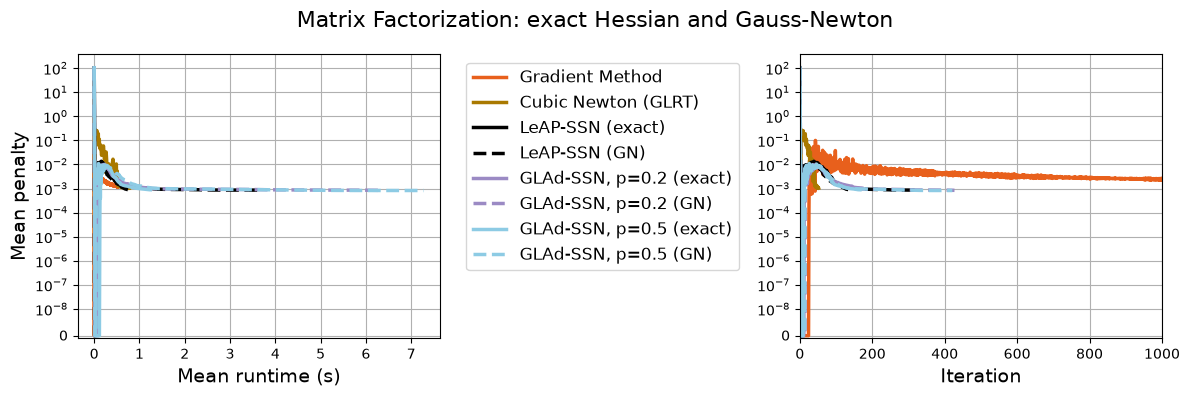

In [227]:
# Select matching exact/Gauss-Newton pairs without changing the original plots.
comparison_names = ["Gradient Method", "Cubic Newton (GLRT)"]
comparison_colors = [colors[0], colors[original_method_names.index("Cubic Newton (GLRT)")]]
comparison_styles = ["-", "-"]
for method_name in gn_base_names:
    color = colors[original_method_names.index(method_name)]
    comparison_names.extend([method_name, f"{method_name} (GN)"])
    comparison_colors.extend([color, color])
    comparison_styles.extend(["-", "--"])

comparison_histories = [averaged_history[name] for name in comparison_names]
comparison_labels = [
    name if name in ("Gradient Method", "Cubic Newton (GLRT)") or name.endswith(" (GN)") else f"{name} (exact)"
    for name in comparison_names
]
comparison_reference = min(np.min(history["func"]) for history in comparison_histories)

for measure, reference, ylabel in [
    ("func", comparison_reference, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        comparison_histories, comparison_labels,
        colors=comparison_colors, linewidths=[2.5] * len(comparison_names),
        linestyles=comparison_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization: exact Hessian and Gauss-Newton",
        max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[f"{measure}_gn"] = fig
    plt.show()
    plt.close(fig)


## Save figures

Set `SAVE_FIGURES=True` to save the six mean plots as PDFs in a new ignored
`parallel_results/` folder. The default only displays them. The final combined
comparison is not included in this export.


In [228]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "parallel_results" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, fig in figures.items():
        fig.savefig(output_dir / f"{measure}.pdf", bbox_inches="tight")
    print("Saved figures to", output_dir)

## Combined gradient comparison

Compare GLAd (`p=0.5`), cubic Newton and gradient descent in two figures:
gradient norm against iteration and against runtime. Edit
`combined_gradient_methods` to choose methods.

- Thick lines: median across seeds.
- Shading: 25th-75th percentiles, showing seed variation, not confidence intervals.
- Faint lines: individual seeds.
- Open circles: last displayed median supported by every seed.

Summaries include all seeds and end at their common recorded endpoint.
Individual traces continue to their own endpoints; no stopped seed is dropped
and no final value is carried forward beyond its recorded end. An early
failure can therefore shorten a median curve even when other seeds continue.

Runtime summaries use the latest observation at each shared timestamp, without
interpolating gradients. Duplicate timestamps use the last observation.
The two figures share a logarithmic gradient scale. Exact zeros are omitted;
`plot_threshold` does not trim these curves.

The iteration view shows up to 150 updates. Set `combined_gradient_max_iter=None`
for all iterations. Runtime shows the full range; use
`combined_gradient_max_time=200` for a 200-second zoom. These controls only
change the display. Figures are stored in `combined_gradient_figures`.

These are diagnostics of the same MF experiment, not extra paper figures.
They read `grad_norm` and `time` from `all_seeds_histories`. Rerun only these
two code cells to change the view when the histories are already available.


In [229]:
def plot_combined_gradient_histories(seed_histories, method_colors, *,
                                     axis="iteration", max_x=None, ylim=None):
    """Overlay per-seed norms, medians and quartiles for selected MF methods.

    seed_histories maps each seed to method histories. ``grad_norm`` and
    ``time`` are equal-length 1-D arrays, starting with the initial point;
    times are cumulative seconds, finite, nonnegative and nondecreasing.
    method_colors maps selected method names to Matplotlib colors.
    axis is 'iteration' or 'runtime'; max_x is an optional inclusive display
    bound in those units. All-seed summaries use common recorded support.
    Runtime uses the latest observation at each common timestamp, including
    the last observation at duplicate times, with no endpoint extrapolation.
    Return a new figure; leave all input histories and earlier plots intact.
    """
    if axis not in ("iteration", "runtime"):
        raise ValueError("axis must be 'iteration' or 'runtime'.")
    if not seed_histories or not method_colors:
        raise ValueError("Select at least one method and collect seed histories first.")
    if max_x is not None and (not np.isfinite(max_x) or max_x < 0):
        raise ValueError("max_x must be finite and nonnegative, or None.")

    runs_by_method = {}
    for method in method_colors:
        runs = []
        for seed, histories_for_seed in seed_histories.items():
            history = histories_for_seed[method]
            g = np.asarray(history["grad_norm"], dtype=float)
            t = np.asarray(history["time"], dtype=float)
            if (g.ndim != 1 or g.size == 0 or t.shape != g.shape
                    or not np.all(np.isfinite(g)) or np.any(g < 0)
                    or not np.all(np.isfinite(t)) or np.any(t < 0)
                    or np.any(np.diff(t) < 0)):
                raise ValueError(f"Invalid gradient/time history for {method}, seed {seed}.")
            runs.append((np.arange(g.size) if axis == "iteration" else t, g))
        runs_by_method[method] = runs

    def positive(values):
        return np.where(values > 0, values, np.nan)

    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    zero_present = False
    no_overlap = []
    for method, color in method_colors.items():
        runs = runs_by_method[method]
        for x, g in runs:
            ax.plot(x, positive(g), color=color, alpha=0.18, linewidth=0.8,
                    drawstyle="steps-post" if axis == "runtime" else "default",
                    marker="." if len(g) == 1 else None, label="_nolegend_")
            zero_present |= bool(np.any(g == 0))

        start = max(x[0] for x, _ in runs)
        end = min(x[-1] for x, _ in runs)
        if max_x is not None:
            end = min(end, max_x)
        if start > end:
            no_overlap.append(method)
            ax.plot([], [], color=color, linewidth=2.3, label=f"{method} (traces only)")
            continue

        if axis == "iteration":
            grid = np.arange(int(end) + 1)
            values = np.stack([g[:len(grid)] for _, g in runs])
        else:
            # Every change inside common support appears in the step summary.
            grid = np.unique(np.concatenate(
                [x[(x >= start) & (x <= end)] for x, _ in runs]
                + [np.array([start, end])]
            ))
            values = np.stack([
                g[np.searchsorted(x, grid, side="right") - 1] for x, g in runs
            ])
        lower, median, upper = np.percentile(values, [25, 50, 75], axis=0)
        ax.fill_between(grid, positive(lower), positive(upper), color=color,
                        alpha=0.16, step="post" if axis == "runtime" else None)
        ax.plot(grid, positive(median), color=color, linewidth=2.4, label=method,
                drawstyle="steps-post" if axis == "runtime" else "default")
        if median[-1] > 0:
            ax.plot(grid[-1], median[-1], marker="o", markersize=5,
                    markerfacecolor="white", markeredgecolor=color,
                    linestyle="none", label="_nolegend_")

    longest = max(x[-1] for runs in runs_by_method.values() for x, _ in runs)
    right = longest if max_x is None else max_x
    ax.set_xlim(0, right if right > 0 else 1)
    ax.set_yscale("log")
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Iteration" if axis == "iteration" else "Runtime (s)")
    ax.set_ylabel("Gradient norm")
    title = f"Matrix factorization: {len(seed_histories)} seeds, gradient vs {axis}"
    runtime_zoomed = axis == "runtime" and max_x is not None and max_x < longest
    if runtime_zoomed:
        title += f" (first {max_x:g} s)"
    fig.suptitle(title)
    ax.set_title("Thick: median | Shaded: 25th-75th percentile | Faint: individual seeds",
                 fontsize=10)
    ax.legend(fontsize=10)
    ax.grid(True, which="major", alpha=0.2)
    note = "Open circles: end of each displayed all-seed summary."
    if runtime_zoomed:
        note += f"\nFull recorded runtime: {longest:,.1f} s; later observations are outside this view."
    if no_overlap:
        note += " No common recorded interval: " + ", ".join(no_overlap) + "."
    if zero_present:
        note += " Exact zeros omitted on the log axis."
    fig.supxlabel(note, fontsize=9)
    return fig


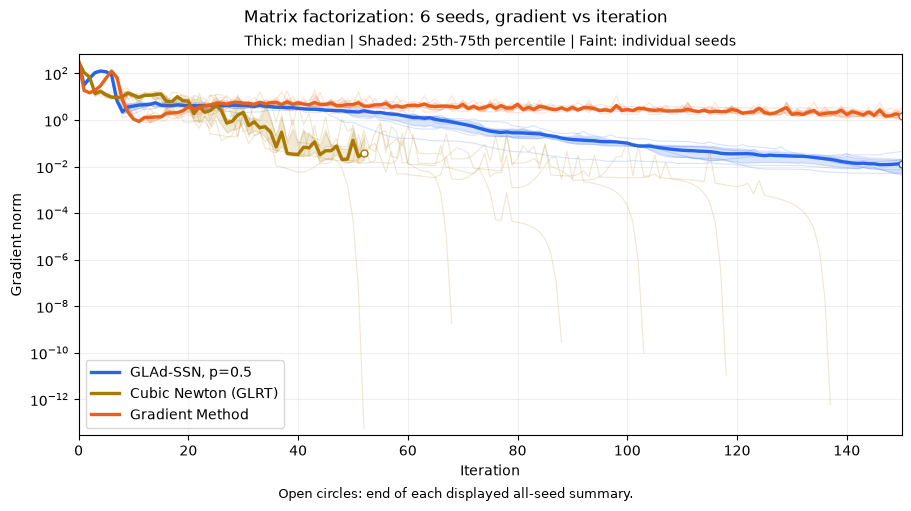

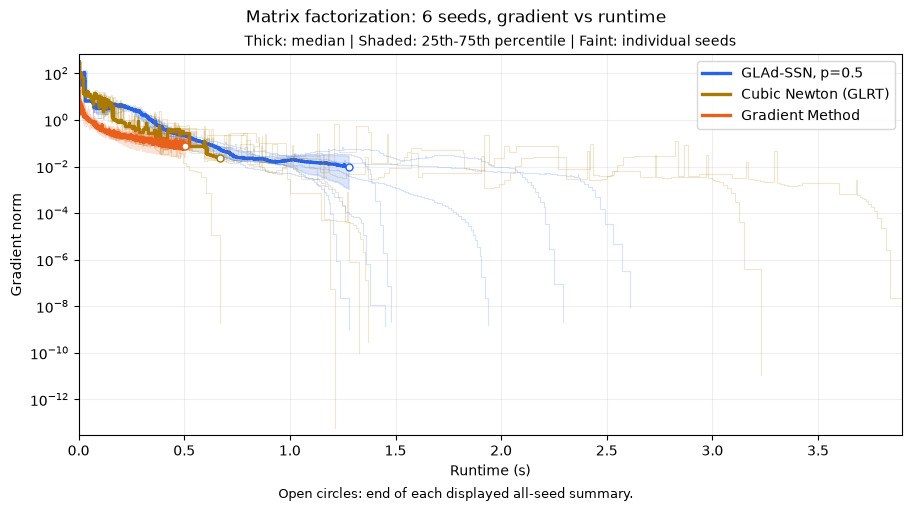

In [230]:
# Change the GLAd key to select another exponent, or add another method/color.
combined_gradient_methods = {
    "GLAd-SSN, p=0.5": "#2563eb",
    "Cubic Newton (GLRT)": "#A97900",
    "Gradient Method": "#E8601C",
}
combined_gradient_max_iter = min(number_of_iterations, 150)  # None: full range.
combined_gradient_max_time = None  # Full range; e.g. 200.0 for a zoom in seconds.

# Share the gradient scale between the iteration and runtime figures.
combined_gradient_extents = []
for combined_seed_histories in all_seeds_histories.values():
    for combined_method in combined_gradient_methods:
        combined_values = np.asarray(combined_seed_histories[combined_method]["grad_norm"])
        combined_positive = combined_values[np.isfinite(combined_values) & (combined_values > 0)]
        if combined_positive.size:
            combined_gradient_extents.append((combined_positive.min(), combined_positive.max()))
combined_gradient_ylim = (
    (0.5 * min(pair[0] for pair in combined_gradient_extents),
     2.0 * max(pair[1] for pair in combined_gradient_extents))
    if combined_gradient_extents else (1e-16, 1.0)
)

combined_gradient_figures = {}
for combined_axis, combined_limit in [
    ("iteration", combined_gradient_max_iter),
    ("runtime", combined_gradient_max_time),
]:
    combined_fig = plot_combined_gradient_histories(
        all_seeds_histories, combined_gradient_methods,
        axis=combined_axis, max_x=combined_limit, ylim=combined_gradient_ylim,
    )
    combined_gradient_figures[combined_axis] = combined_fig
    plt.show()
    plt.close(combined_fig)


## Validation

The gradient-tolerance update passed 62 tests. A fresh-kernel check ran all
11 methods on seeds 549 and 498, with dimensions `(6, 4, 2)`, 300 gradient
updates and 100 Newton updates, using two workers and one library thread each.
Objective, gradient and penalty histories matched the old runs exactly up
to the first threshold crossing. With `grad_tol=None`, full histories, cubic
diagnostics and statuses matched exactly. Failures above the target retained
their failure statuses. LeAP now uses the same inclusive `<=` tolerance check
as the other methods; existing solver defaults remain `None`.

A separate full-size cubic run for seed 33, using the settings below the
parameter table, stopped after 109 updates at gradient norm `2.953e-13`.
Its objective was `4876.564829316686`, penalty `0.006892844592017084`, and
work count 76,638 Hessian-vector products. One-thread wall time measured with
`perf_counter` was 14.51 s; background load was uncontrolled. This is not a
benchmark against the earlier parallel run or a full paper reproduction.

Environment: Windows, Intel Core i7-11800H, float64, Python 3.12.14,
NumPy 2.4.6, SciPy 1.18.0, Matplotlib 3.11.0, Joblib 1.5.3 and GALAHAD 5.5.3.
Original outputs and detailed checks remain in the ignored local
`_diagnostics_archive/gradient_tolerance_20261102_110358/` folder.


## Representative actual run

These supplementary plots show one **actual seed**, shared by every method and
metric. The existing averages remain: the local manuscript's Appendix E.2,
Figure 7 reports 20-seed means. Current settings differ from that experiment.

Selection uses a **medoid**: the seed closest to the other seeds. At each fixed
gradient target, rank seeds by their first-hit iteration; unreached targets tie
last. Select the seed with the smallest average absolute rank distance, giving
equal weight to four method families and all targets. Smallest seed breaks ties.
Runtime does not influence selection. This is a documented diagnostic rule,
not a universal representative-run standard; penalty behavior need not be typical.
See [Kaufman and Rousseeuw (1987)](https://wis.kuleuven.be/stat/robust/papers/publications-1987/kaufmanrousseeuw-clusteringbymedoids-l1norm-1987.pdf).

The figures use actual recorded curves, without averaging, truncating to the
shortest run, or extending stopped runs. Runtime shows the complete histories;
the iteration view starts with a labelled 150-update zoom (set its limit to None
for the full range). The objective reference is the best
observed value for this seed across the plotted methods. Open circles mark run
endpoints. Zeros remain visible on a scale linear near zero and logarithmic above.
Reuse the completed histories by running only this section. Details and figure
mapping to [arXiv v1, Section 5.2 / Appendix E.2](https://arxiv.org/abs/2602.08069v1)
are in `CUBIC_SUBPROBLEM.md`.


In [231]:
from representative_plots import (
    select_representative_seed, target_summary,
    plot_representative_runs, plot_target_times,
)
import pandas as pd
import json

# Selection settings: one method per family; runtime does not affect selection.
representative_selection_methods = [
    "Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5", "Cubic Newton (GLRT)",
]
representative_gradient_targets = [1e2, 1.0, 1e-2, 1e-4, 1e-6, 1e-8]
representative_plot_methods = list(original_method_names)
representative_seed_override = None  # An explicit seed is labelled "example".
comparison_gradient_target = 1e-6     # Reporting target, not the solver grad_tol.
representative_zero_scale = 1e-14
representative_max_iter = 150          # Display zoom only; None shows the full run.
representative_max_time = None

if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete the seed batch before selecting a representative run.")
representative_selection = select_representative_seed(
    all_seeds_histories, representative_selection_methods, representative_gradient_targets)
representative_seed = (representative_selection["seed"] if representative_seed_override is None
                       else int(representative_seed_override))
representative_label = "Representative" if representative_seed_override is None else "Example"
print(f"{representative_label} seed: {representative_seed}")
if representative_seed_override is None and len(representative_selection["tied_seeds"]) > 1:
    print("Tied medoids:", representative_selection["tied_seeds"], "-- using the smallest seed.")
if not representative_selection["informative"]:
    print("The milestone ranks do not distinguish these seeds; there is no unique typical run.")
selection_scores = pd.DataFrame([
    {"seed": seed, "medoid score": score, "shown": seed == representative_seed}
    for seed, score in representative_selection["scores"].items()
])
display(selection_scores.style.format({"medoid score": "{:.4f}"}))


Representative seed: 989


,seed,medoid score,shown
0,33,0.3400,False
1,483,0.3283,False
2,498,0.2833,False
3,528,0.2967,False
4,549,0.2850,False
5,989,0.2633,True


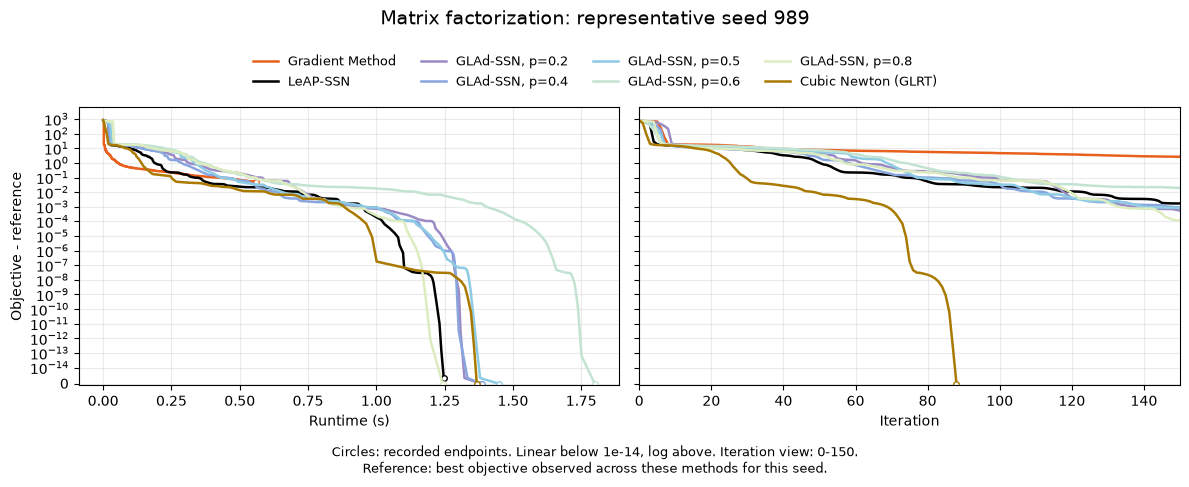

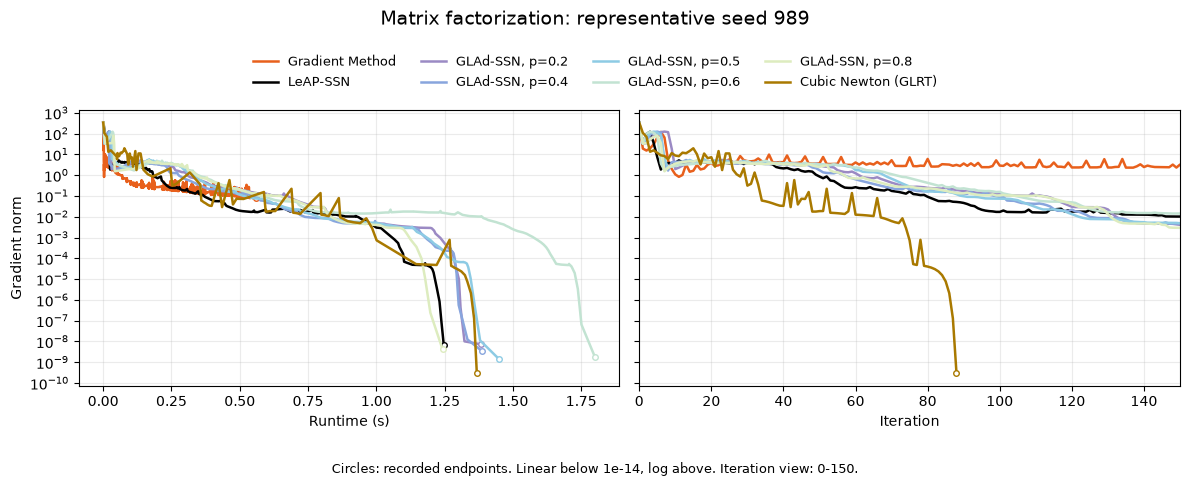

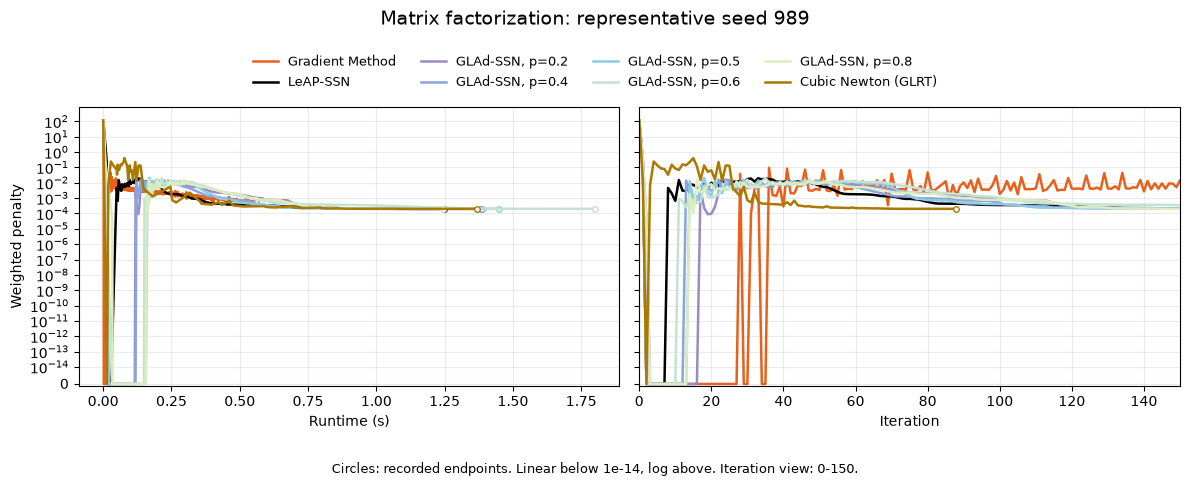

Reporting target: 1e-06; actual solver grad_tol: 1e-08


,method,reached,hit_iteration,hit_time,final_gradient,final_penalty,status
40,Gradient Method,False,--,--,7.820e-02,5.490e-04,iterations_exceeded
41,LeAP-SSN,True,188,1.23,6.788e-09,2.007e-04,"success, 190 iters"
42,"GLAd-SSN, p=0.2",True,178,1.31,7.199e-09,2.007e-04,"success, 180 iters"
43,"GLAd-SSN, p=0.4",True,194,1.3,3.413e-09,2.007e-04,"success, 196 iters"
44,"GLAd-SSN, p=0.5",True,189,1.36,1.383e-09,2.007e-04,"success, 191 iters"
45,"GLAd-SSN, p=0.6",True,245,1.75,1.845e-09,2.007e-04,"success, 246 iters"
46,"GLAd-SSN, p=0.8",True,166,1.2,4.108e-09,2.007e-04,"success, 167 iters"
47,Cubic Newton (GLRT),True,87,1.36,2.983e-10,2.007e-04,"success, 88 iters"


In [232]:
# Same colors as the mean figures; optional GN methods use matching dashed lines.
representative_base_colors = dict(zip(original_method_names, [
    "#E8601C", "black", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF", "#A97900",
]))
representative_styles = {
    name: dict(color=representative_base_colors[name.removesuffix(" (GN)")],
               linestyle="--" if name.endswith(" (GN)") else "-")
    for name in representative_plot_methods
}
representative_figures = plot_representative_runs(
    all_seeds_histories, representative_seed, representative_styles,
    zero_scale=representative_zero_scale,
    max_iter=representative_max_iter, max_time=representative_max_time,
    selection_label=representative_label,
)
for representative_figure in representative_figures.values():
    display(representative_figure)
    plt.close(representative_figure)

representative_target_rows = target_summary(
    all_seeds_histories, representative_plot_methods,
    comparison_gradient_target, all_seeds_statuses)
representative_target_table = pd.DataFrame(representative_target_rows)
print(f"Reporting target: {comparison_gradient_target:g}; actual solver grad_tol: "
      f"{run_metadata['configuration']['grad_tol']}")
display(representative_target_table.loc[
    representative_target_table.seed == representative_seed,
    ["method", "reached", "hit_iteration", "hit_time", "final_gradient", "final_penalty", "status"],
].style.format({"hit_iteration": "{:.0f}", "hit_time": "{:.3g}",
                "final_gradient": "{:.3e}", "final_penalty": "{:.3e}"}, na_rep="--"))


### Check every seed

The dots below show the first recorded time each run reached the reporting
gradient target. Crosses mean **not reached** and sit at that run's last recorded
time; they are not time-to-target estimates. Rings identify the selected seed.
Counts include all seeds. A first hit does not imply the solver eventually
reported convergence; final gradients and exit statuses remain in the table.
Parallel timings include shared CPU load.


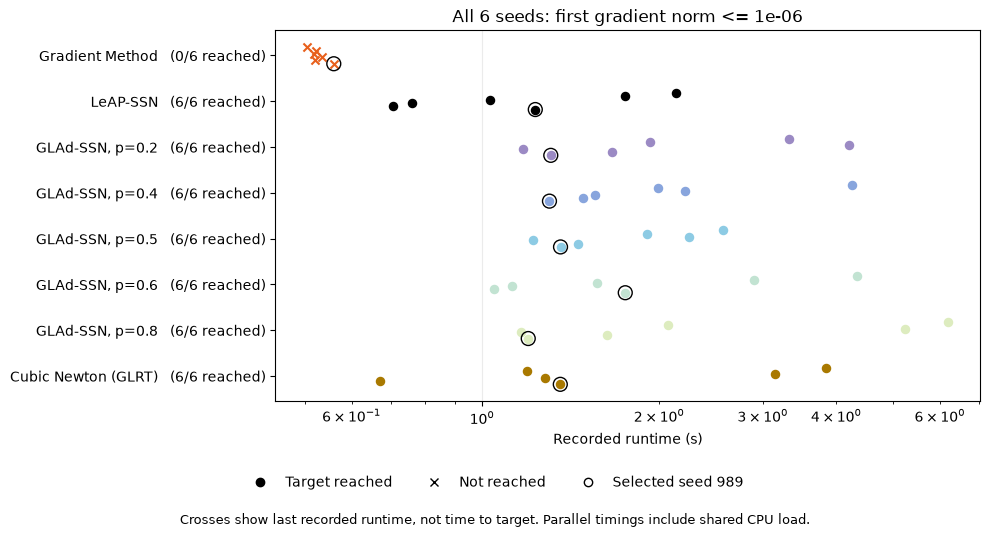

seed,method,reached,hit_iteration,hit_time,final_gradient,final_penalty,iterations,runtime,status
33,Gradient Method,False,--,--,0.037,0.00082,3000,0.505,iterations_exceeded
33,LeAP-SSN,True,293,2.14,7.53e-09,1.54e-05,294,2.15,"success, 294 iters"
33,"GLAd-SSN, p=0.2",True,371,3.33,1.38e-09,1.54e-05,373,3.37,"success, 373 iters"
33,"GLAd-SSN, p=0.4",True,432,4.25,2.01e-09,1.54e-05,433,4.29,"success, 433 iters"
33,"GLAd-SSN, p=0.5",True,298,2.57,9.11e-09,1.54e-05,299,2.61,"success, 299 iters"
33,"GLAd-SSN, p=0.6",True,326,4.34,5.93e-10,1.54e-05,328,4.43,"success, 328 iters"
33,"GLAd-SSN, p=0.8",True,412,6.19,1.75e-09,1.54e-05,414,6.32,"success, 414 iters"
33,Cubic Newton (GLRT),True,136,3.84,6e-13,1.54e-05,137,3.9,"success, 137 iters"
483,Gradient Method,False,--,--,0.0553,0.000549,3000,0.521,iterations_exceeded
483,LeAP-SSN,True,243,1.75,6.53e-09,0.000288,245,1.78,"success, 245 iters"


In [233]:
representative_figures["target_times"] = plot_target_times(
    representative_target_rows, representative_styles,
    comparison_gradient_target, representative_seed)
display(representative_figures["target_times"])
plt.close(representative_figures["target_times"])
display(HTML("<details><summary>All seed results and exit statuses</summary>" +
             representative_target_table.to_html(index=False, na_rep="--", float_format=lambda x: f"{x:.3g}") +
             "</details>"))

# Save independently of earlier figures, including enough information to audit selection.
if SAVE_FIGURES:
    representative_output_dir = MF_DIR / "parallel_results" / ("representative_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    representative_output_dir.mkdir(parents=True, exist_ok=False)
    for name, fig in representative_figures.items():
        fig.savefig(representative_output_dir / f"{name}.pdf", bbox_inches="tight")
    representative_record = dict(
        selection=representative_selection, displayed_seed=representative_seed,
        selection_label=representative_label, plotted_methods=representative_plot_methods,
        reporting_gradient_target=comparison_gradient_target,
        zero_scale=representative_zero_scale,
        max_iter=representative_max_iter, max_time=representative_max_time,
        run_metadata=run_metadata, results=representative_target_rows,
    )
    (representative_output_dir / "selection.json").write_text(
        json.dumps(representative_record, indent=2, allow_nan=False), encoding="utf-8")
    print("Saved representative figures and selection record to", representative_output_dir)


## Mean with terminal values retained

Every seed stays in the arithmetic mean. Stopped runs contribute their actual
final gradient norm while other seeds continue. Each method's curve ends when
**all seeds are at or below `mean_gradient_target`**, or at that method's last
recorded point if the target is missed. No extra flat tail is added afterward.

The target defaults to the completed batch's `grad_tol`; changing it here only
changes the display. Missed targets are listed below the figure. Full numeric
means and cutoff details remain in `mean_gradient_summaries`.

Runtime uses the latest recorded value at each shared time. The two axis limits
only zoom the view. LeAP-SSN is black; GLAd exponents are `0.2, 0.4, 0.5, 0.6, 0.8`.
Matching Gauss-Newton curves use the same color with dashed lines. Only variants
recorded for every seed are shown; current GN exponents are `0.2, 0.5`.


Not recorded for every seed: GLAd-SSN, p=0.4 (GN), GLAd-SSN, p=0.6 (GN), GLAd-SSN, p=0.8 (GN)
For more GN pairs, include their p values in gn_exponents and rerun the seed batch.


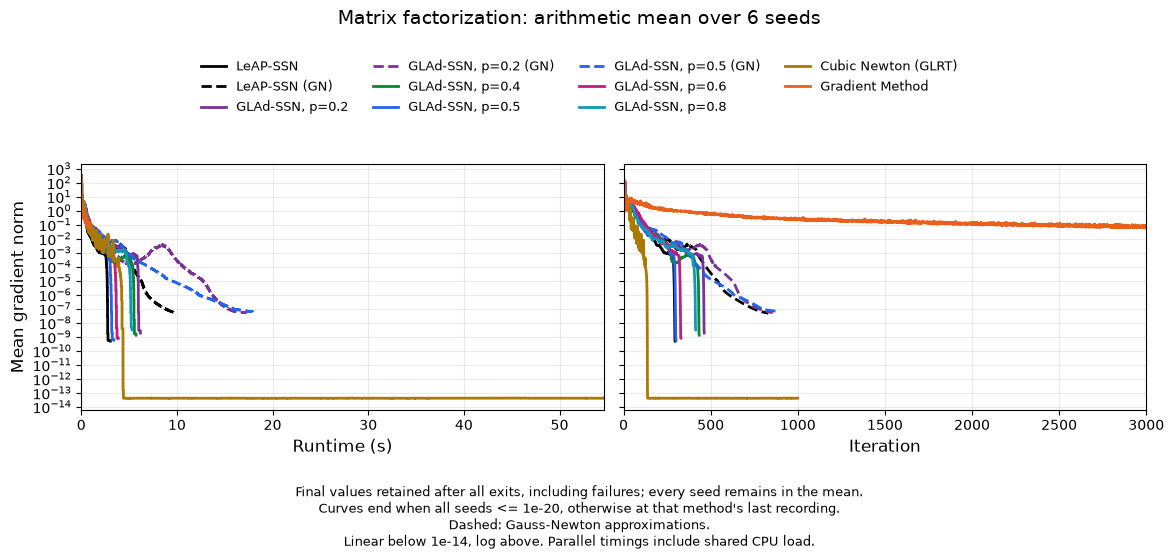

Plot cutoff: every seed's gradient norm <= 1e-20
runtime: target missed; ending at last recording: LeAP-SSN, LeAP-SSN (GN), GLAd-SSN, p=0.2, GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.4, GLAd-SSN, p=0.5, GLAd-SSN, p=0.5 (GN), GLAd-SSN, p=0.6, GLAd-SSN, p=0.8, Cubic Newton (GLRT), Gradient Method
iteration: target missed; ending at last recording: LeAP-SSN, LeAP-SSN (GN), GLAd-SSN, p=0.2, GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.4, GLAd-SSN, p=0.5, GLAd-SSN, p=0.5 (GN), GLAd-SSN, p=0.6, GLAd-SSN, p=0.8, Cubic Newton (GLRT), Gradient Method


In [ ]:
from mean_plots import plot_mean_gradient_histories

if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete the seed batch before computing the mean.")

# Same color for each exact/Gauss-Newton pair; dashed lines mark GN.
mean_gradient_p_colors = {
    0.2: "#7B3294", 0.4: "#008837", 0.5: "#2563eb",
    0.6: "#C51B7D", 0.8: "#1497B7",
}
mean_gradient_base_colors = {"LeAP-SSN": "black"}
mean_gradient_base_colors.update({f"GLAd-SSN, p={p:g}": color for p, color in mean_gradient_p_colors.items()})
mean_gradient_methods = {}
mean_gradient_missing = []
for base_name, color in mean_gradient_base_colors.items():
    for suffix in ("", " (GN)"):
        name = base_name + suffix
        if all(name in histories for histories in all_seeds_histories.values()):
            mean_gradient_methods[name] = color
        else:
            mean_gradient_missing.append(name)
mean_gradient_methods.update({"Cubic Newton (GLRT)": "#A97900", "Gradient Method": "#E8601C"})
mean_gradient_linestyles = {
    name: "--" if name.endswith(" (GN)") else "-" for name in mean_gradient_methods
}
if mean_gradient_missing:
    print("Not recorded for every seed:", ", ".join(mean_gradient_missing))
    print("For more GN pairs, include their p values in gn_exponents and rerun the seed batch.")
mean_gradient_target = run_metadata["configuration"]["grad_tol"]  # Display cutoff; solver unchanged.
mean_gradient_max_iter = None  # Full displayed range; e.g. 150 for a zoom.
mean_gradient_max_time = None  # Full displayed range; e.g. 200 for a zoom in seconds.

mean_gradient_figure, mean_gradient_summaries = plot_mean_gradient_histories(
    all_seeds_histories, mean_gradient_methods,
    max_iter=mean_gradient_max_iter, max_time=mean_gradient_max_time,
    method_linestyles=mean_gradient_linestyles, target=mean_gradient_target,
)
display(mean_gradient_figure)
plt.close(mean_gradient_figure)
if mean_gradient_target is not None:
    print(f"Plot cutoff: every seed's gradient norm <= {mean_gradient_target:g}")
    for axis, summary in mean_gradient_summaries.items():
        missed = [name for name, endpoint in summary["endpoints"].items()
                  if not endpoint["all_seeds_reached"]]
        if missed:
            print(f"{axis}: target missed; ending at last recording:", ", ".join(missed))

if SAVE_FIGURES:
    import json
    mean_gradient_output_dir = MF_DIR / "parallel_results" / ("mean_gradient_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    mean_gradient_output_dir.mkdir(parents=True, exist_ok=False)
    mean_gradient_figure.savefig(mean_gradient_output_dir / "mean_gradient.pdf", bbox_inches="tight")
    mean_gradient_record = dict(
        convention="All-seed arithmetic mean; final values held until all seeds meet target or this method ends",
        gradient_target=mean_gradient_target,
        seeds=list(seeds_to_try), methods=list(mean_gradient_methods),
        linestyles=mean_gradient_linestyles, missing_methods=mean_gradient_missing,
        max_iter=mean_gradient_max_iter, max_time=mean_gradient_max_time,
        run_metadata=run_metadata, statuses=all_seeds_statuses,
        summaries={axis: dict(grid=summary["grid"].tolist(), endpoints=summary["endpoints"],
                             means={name: values.tolist() for name, values in summary["means"].items()})
                   for axis, summary in mean_gradient_summaries.items()},
    )
    (mean_gradient_output_dir / "mean_gradient.json").write_text(
        json.dumps(mean_gradient_record, indent=2, allow_nan=False), encoding="utf-8")
    print("Saved mean figure and data to", mean_gradient_output_dir)
